<a href="https://colab.research.google.com/github/Woobak-p/test1/blob/main/%EC%B6%94%EA%B0%80%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
graph = {
    '김윤채': ['이지민', '최시훈', '김다경'],
    '이지민': ['노다운', '김성연', '한진주'],
    '최영희': ['하지민', '신지민', '조연주'],
    '양다영': ['김희진', '조수아', '정우진'],
    '박건우': ['이준서', '최지훈', '전민성'],
    '김근영': ['김윤채', '목은혜', '박건우'],
    '김성연': ['이재은', '유채영', '최영희'],
    '조연주': ['양다영', '김지은', '고소현'],
    '목은혜': ['고가은', '이준서', '김근영'],
    '김다경': ['정우진', '곽지후', '이지민'],
    '노다운': ['최시훈', '한진주', '하지민'],
    '이재은': ['신지민', '박은영', '허남재'],
    '최시훈': ['김희진', '조수아', '김지은'],
    '유채영': ['고소현', '고가은', '이준서'],
    '한진주': ['최지훈', '전민성', '곽지후'],
    '하지민': ['김윤채', '김근영', '김성연'],
    '신지민': ['조연주', '목은혜', '김다경'],
    '박은영': ['노다운', '이재은', '최시훈'],
    '허남재': ['유채영', '한진주', '하지민'],
    '김희진': ['신지민', '박은영', '허남재'],
    '조수아': ['양다영', '박건우', '김근영'],
    '김지은': ['김성연', '조연주', '목은혜'],
    '고소현': ['김다경', '노다운', '이재은'],
    '고가은': ['최시훈', '유채영', '한진주'],
    '이준서': ['하지민', '신지민', '박은영'],
    '정우진': ['허남재', '김희진', '조수아'],
    '최지훈': ['김지은', '고소현', '고가은'],
    '전민성': ['이준서', '정우진', '최지훈'],
    '곽지후': ['전민성', '김윤채', '이지민']
}

In [2]:
from collections import deque

In [3]:
def dfs(graph,v,visited):
  visited.add(v)
  print(v,end=' ')
  for neighbor in graph[v]:
    if neighbor not in visited:
      dfs(graph,neighbor,visited)

In [4]:
print("DFS 탐색 순서:")
dfs(graph,'김윤채',set())

DFS 탐색 순서:
김윤채 이지민 노다운 최시훈 김희진 신지민 조연주 양다영 조수아 박건우 이준서 하지민 김근영 목은혜 고가은 유채영 고소현 김다경 정우진 허남재 한진주 최지훈 김지은 김성연 이재은 박은영 최영희 전민성 곽지후 

In [5]:
def bfs(graph,start):
  visited = set()
  queue = deque([start])
  visited.add(start)

  while queue:
    v = queue.popleft()
    print(v, end=' ')
    for neighbor in graph[v]:
      if neighbor not in visited:
        visited.add(neighbor)
        queue.append(neighbor)

In [6]:
print("\nBFS 탐색 순서:")
bfs(graph,'김윤채')


BFS 탐색 순서:
김윤채 이지민 최시훈 김다경 노다운 김성연 한진주 김희진 조수아 김지은 정우진 곽지후 하지민 이재은 유채영 최영희 최지훈 전민성 신지민 박은영 허남재 양다영 박건우 김근영 조연주 목은혜 고소현 고가은 이준서 

In [7]:
def infection_simulation(graph, start_patient):
    # 각 노드까지의 거리를 저장할 딕셔너리 (방문 처리 겸용)
    distances = {start_patient: 0}
    queue = deque([start_patient])

    while queue:
        current = queue.popleft()
        current_dist = distances[current]

        # 2단계까지만 탐색하므로, 현재 거리가 2이면 이웃을 더 탐색하지 않음
        if current_dist >= 2:
            continue

        for neighbor in graph.get(current, []):
            if neighbor not in distances:
                distances[neighbor] = current_dist + 1
                queue.append(neighbor)

    # 감염자 자신(거리 0) 제외하고 출력하기
    print(f"최초 감염자: {start_patient}\n")
    print("== 2단계 이내 감염 예상 대상자 목록 ==")

    # 거리순(레벨순)으로 보기 좋게 정렬하여 출력
    sorted_targets = sorted(
        [(name, dist) for name, dist in distances.items() if dist > 0],
        key=lambda x: (x[1], x[0])
    )

    for name, dist in sorted_targets:
        print(f"- {name} (감염 경로 거리: {dist}단계)")

infection_simulation(graph, '김윤채')

최초 감염자: 김윤채

== 2단계 이내 감염 예상 대상자 목록 ==
- 김다경 (감염 경로 거리: 1단계)
- 이지민 (감염 경로 거리: 1단계)
- 최시훈 (감염 경로 거리: 1단계)
- 곽지후 (감염 경로 거리: 2단계)
- 김성연 (감염 경로 거리: 2단계)
- 김지은 (감염 경로 거리: 2단계)
- 김희진 (감염 경로 거리: 2단계)
- 노다운 (감염 경로 거리: 2단계)
- 정우진 (감염 경로 거리: 2단계)
- 조수아 (감염 경로 거리: 2단계)
- 한진주 (감염 경로 거리: 2단계)


In [8]:
import random
from collections import deque

# 1. 기존 'graph'에 있던 고유 이름 목록 추출
original_names = list(graph.keys())

# 2. 기존 이름들을 변형하거나 확장하여 100개 내외의 고유 이름 리스트 생성 (기존 이름 유지)
extended_names = set(original_names)
surnames = ['김', '이', '박', '최', '정', '강', '조', '윤', '장', '임', '신', '한', '오', '서']
given_names = ['민', '서', '예', '지', '신', '현', '우', '진', '재', '하', '기', '성', '동', '승', '영', '태', '정', '채', '은', '수', '호', '율', '빈', '아', '은', '준']

random.seed(42)
while len(extended_names) < 100:
    new_name = random.choice(surnames) + random.choice(given_names) + random.choice(given_names)
    extended_names.add(new_name)

large_node_list = list(extended_names)
large_graph = {node: [] for node in large_node_list}

# 3. 각 노드별로 무작위 이웃(간선)을 2~4개 연결하여 10단계 이상의 전파가 가능한 그래프 설계
for node in large_node_list:
    possible_neighbors = [n for n in large_node_list if n != node]
    num_edges = random.randint(2, 3)
    large_graph[node] = random.sample(possible_neighbors, num_edges)

# 4. Max Depth 조절 가능한 감염 시뮬레이션 함수
def infection_simulation_custom(graph, start_patient, max_depth=10):
    if start_patient not in graph:
        print(f"그래프에 '{start_patient}' 노드가 존재하지 않습니다.")
        return

    distances = {start_patient: 0}
    queue = deque([start_patient])

    while queue:
        current = queue.popleft()
        current_dist = distances[current]

        # 최대 깊이(max_depth)에 도달하면 이웃 전파 중단
        if current_dist >= max_depth:
            continue

        for neighbor in graph.get(current, []):
            if neighbor not in distances:
                distances[neighbor] = current_dist + 1
                queue.append(neighbor)

    print(f"최초 감염자: {start_patient}")
    print(f"== {max_depth}단계 이내 감염 예상 대상자 통계 (총 {len(distances) - 1}명) ==\n")

    # 각 단계별 감염자 수 집계
    depth_counts = {}
    for name, dist in distances.items():
        if dist > 0:
            depth_counts[dist] = depth_counts.get(dist, 0) + 1

    for d in range(1, max_depth + 1):
        count = depth_counts.get(d, 0)
        print(f"[{d}단계 감염자 수]: {count}명")

    # 정렬하여 상위 일부 대상자 출력
    sorted_targets = sorted(
        [(name, dist) for name, dist in distances.items() if dist > 0],
        key=lambda x: (x[1], x[0])
    )

    print("\n-- 세부 대상자 목록 (최대 20명 출력) --")
    for name, dist in sorted_targets[:20]:
        print(f"- {name} ({dist}단계)")

    if len(sorted_targets) > 20:
        print(f"... 외 {len(sorted_targets) - 20}명 생략")

# 기존 그래프에 있던 '김윤채'를 시작 노드로 설정하여 시뮬레이션 작동
infection_simulation_custom(large_graph, '김윤채', max_depth=10)

최초 감염자: 김윤채
== 10단계 이내 감염 예상 대상자 통계 (총 89명) ==

[1단계 감염자 수]: 3명
[2단계 감염자 수]: 7명
[3단계 감염자 수]: 16명
[4단계 감염자 수]: 23명
[5단계 감염자 수]: 20명
[6단계 감염자 수]: 9명
[7단계 감염자 수]: 6명
[8단계 감염자 수]: 4명
[9단계 감염자 수]: 1명
[10단계 감염자 수]: 0명

-- 세부 대상자 목록 (최대 20명 출력) --
- 양다영 (1단계)
- 오기동 (1단계)
- 한영채 (1단계)
- 김성연 (2단계)
- 서민은 (2단계)
- 신승수 (2단계)
- 이율아 (2단계)
- 조연주 (2단계)
- 조진영 (2단계)
- 허남재 (2단계)
- 박건우 (3단계)
- 박은영 (3단계)
- 박정지 (3단계)
- 서지신 (3단계)
- 서진지 (3단계)
- 서호하 (3단계)
- 신재빈 (3단계)
- 오현빈 (3단계)
- 장아진 (3단계)
- 장예은 (3단계)
... 외 69명 생략


In [9]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# 한글 폰트 설정 (Colab 환경 대응)
!apt-get -y install fonts-nanum
import matplotlib.font_manager as fm

# 나눔 폰트 경로 등록
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
font_name = fm.FontProperties(fname=font_path).get_name()
plt.rc('font', family=font_name)
plt.rcParams['axes.unicode_minus'] = False

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 4s (2,749 kB/s)
Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


/tmp/ipykernel_721/3821398230.py:60: UserWarning: Glyph 45432 (\N{HANGUL SYLLABLE NO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_721/3821398230.py:60: UserWarning: Glyph 46300 (\N{HANGUL SYLLABLE DEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_721/3821398230.py:60: UserWarning: Glyph 44508 (\N{HANGUL SYLLABLE GYU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_721/3821398230.py:60: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_721/3821398230.py:60: UserWarning: Glyph 44048 (\N{HANGUL SYLLABLE GAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_721/3821398230.py:60: UserWarning: Glyph 50684 (\N{HANGUL SYLLABLE YEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_721/3821398230.py:60: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/

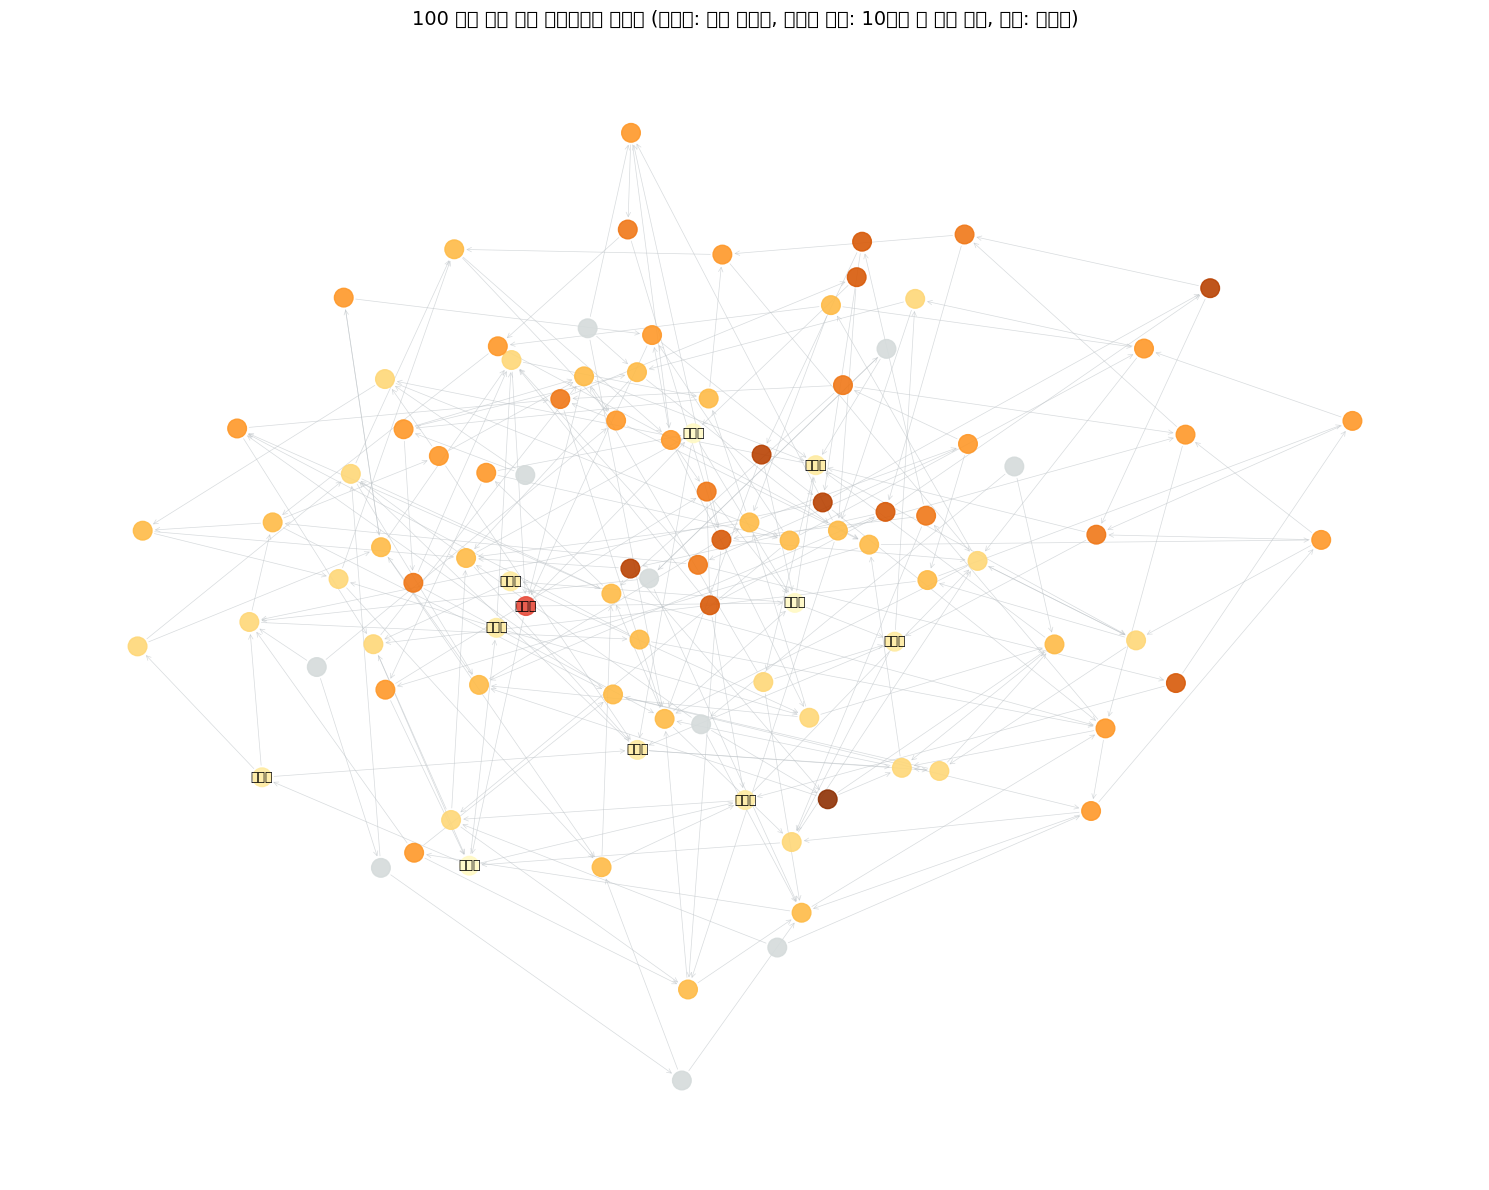

In [10]:
# NetworkX 그래프 생성 및 데이터 추가
G = nx.DiGraph() # 방향성이 있는 유향 그래프
for node, neighbors in large_graph.items():
    G.add_node(node)
    for neighbor in neighbors:
        G.add_edge(node, neighbor)

# 시뮬레이션을 통해 각 노드별 감염 단계(거리)를 재계산
start_patient = '김윤채'
distances = {start_patient: 0}
queue = deque([start_patient])

while queue:
    current = queue.popleft()
    current_dist = distances[current]
    if current_dist >= 10:
        continue
    for neighbor in large_graph.get(current, []):
        if neighbor not in distances:
            distances[neighbor] = current_dist + 1
            queue.append(neighbor)

# 감염되지 않은 노드는 최댓값인 11로 처리하여 시각화 분리
for node in G.nodes():
    if node not in distances:
        distances[node] = 11

# 그래프 시각화 레이아웃 설정
plt.figure(figsize=(15, 12))
pos = nx.spring_layout(G, k=0.15, seed=42)

# 거리별로 색상 지정 (진할수록 초기 감염에 가까움, 미감염은 회색)
node_colors = []
for node in G.nodes():
    dist = distances[node]
    if dist == 0:
        node_colors.append('#e74c3c') # 최초 감염자 (빨간색)
    elif dist == 11:
        node_colors.append('#d5dbdb') # 미감염자 (연한 회색)
    else:
        # 단계가 진행될수록 밝은 오렌지/노란 계열로 변하는 그라데이션 구현
        # 1단계 -> 10단계 매핑
        color_val = min(dist / 10.0, 1.0)
        node_colors.append(plt.cm.YlOrBr(color_val))

# 노드 및 간선 그리기
nx.draw_networkx_nodes(G, pos, node_size=180, node_color=node_colors, alpha=0.9)
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=8, edge_color='#bdc3c7', width=0.5, alpha=0.6)

# 가독성을 위해 일부 주요 노드 이름(최초 및 1, 2단계 감염자)만 레이블로 표시
labels = {}
for node in G.nodes():
    if distances[node] <= 2:
        labels[node] = node

nx.draw_networkx_labels(G, pos, labels, font_size=9, font_family=font_name, font_weight='bold')

plt.title("100 노드 규모 감염 시뮬레이션 시각화 (빨간색: 최초 감염자, 오렌지 계열: 10단계 내 전파 경로, 회색: 미감염)", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()

In [13]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 1. 설치한 나눔바른고딕 폰트 파일을 직접 등록
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
fm.fontManager.addfont(font_path)

# 2. 전역 폰트 및 마이너스 기호 설정
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

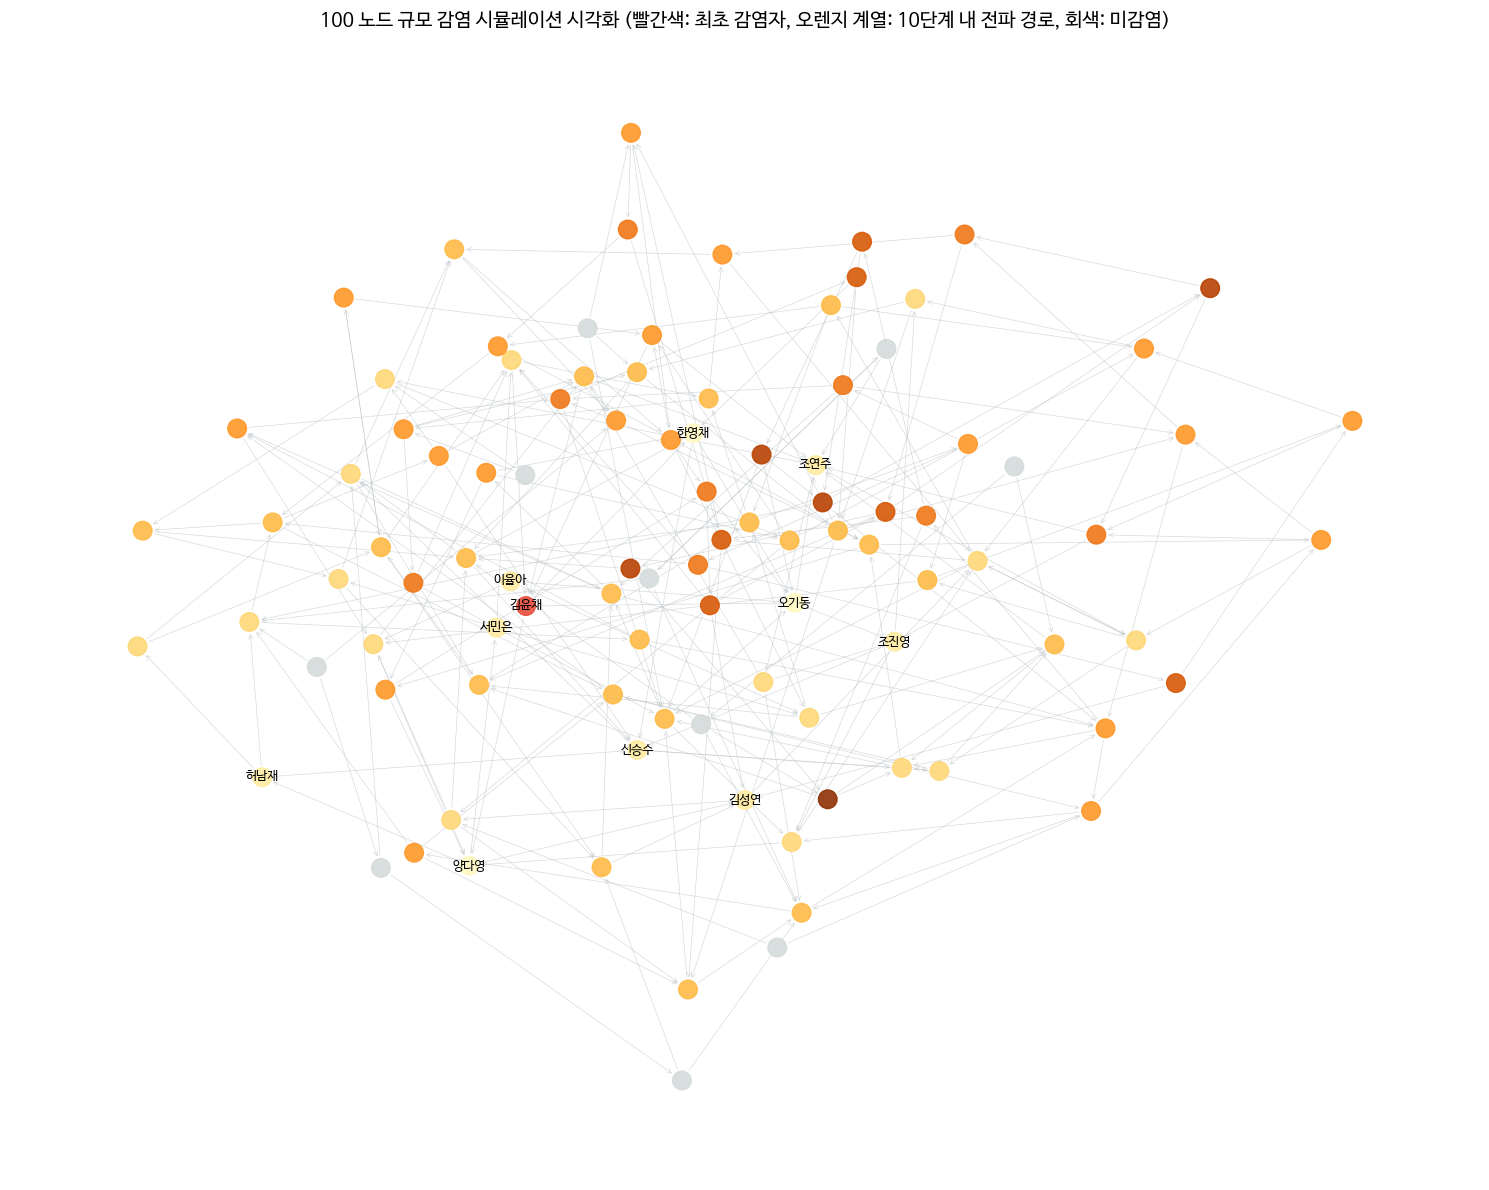

In [14]:
# 3. 폰트 설정을 명시적으로 적용하여 다시 시각화 실행
plt.figure(figsize=(15, 12))
pos = nx.spring_layout(G, k=0.15, seed=42)

# 노드 및 간선 그리기
nx.draw_networkx_nodes(G, pos, node_size=180, node_color=node_colors, alpha=0.9)
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=8, edge_color='#bdc3c7', width=0.5, alpha=0.6)

# 레이블 폰트 설정 포함
labels = {}
for node in G.nodes():
    if distances[node] <= 2:
        labels[node] = node

nx.draw_networkx_labels(
    G, pos, labels,
    font_size=9,
    font_family='NanumBarunGothic',
    font_weight='bold'
)

plt.title("100 노드 규모 감염 시뮬레이션 시각화 (빨간색: 최초 감염자, 오렌지 계열: 10단계 내 전파 경로, 회색: 미감염)", fontsize=14, fontfamily='NanumBarunGothic')
plt.axis('off')
plt.tight_layout()
plt.show()